# Multi-Agent Visual Question Answering with Retrieval-Augmented Generation

The goal of this project is to investigate whether combining visual understanding with external knowledge retrieval can improve answers to image-related questions.

The system combines three main components:

- BLIP-2 for image captioning and visual question answering.

- Llama 3 for question generation and answer integration.

- ChromaDB for retrieving relevant information from a knowledge base.

The notebook walks through dataset preparation, individual component experiments, knowledge-base construction, and the final multi-agent pipeline. It concludes with an evaluation of the resulting system.

**Reproducibility note:** The FVQA dataset is not included in this repository and must be downloaded separately before rerunning the experiments. Reproducing the results therefore requires this additional manual step. Previously generated notebook outputs are preserved for reference.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
import os
from typing import List, Optional, TypeAlias

model_names = ["LLAMA_2_13b_chat", "LLAMA_3_8b", "LLAMA_3_8b_chat"]
model_paths_list = ["/kaggle/input/llama-2/pytorch/13b-chat-hf/1",
                    "/kaggle/input/llama-3/transformers/8b-hf/1",
                    "/kaggle/input/llama-3/transformers/8b-chat-hf/1"]
model_paths = dict(zip(model_names, model_paths_list))
MODEL_NAME = "LLAMA_3_8b_chat"

In [ ]:
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from tqdm import tqdm
import json


def read_json_structure(path, multiple_answers: bool):
    with open(path, 'r') as file:
        structure = json.load(file)

    data = []
    for case in structure.values():
        q = case['question']
        f = case['img_file']
        a = case['answers'] if multiple_answers else [case['answer']]
        data.append(tuple([q, a, f]))
    return data


def list_train_images():
    train_images = "/kaggle/input/fvqa-base/Name_Lists/train_list_0.txt"
    train_images_list = []

    with open(train_images, 'r') as file:
        lines = file.readlines()
        train_images_list.extend(line.strip() for line in lines)
    return train_images_list[:15]


class FVQA(Dataset):
    '''
    # Example usage:
    img_shapes = set()
    for q, a, f, i in tqdm(dataset):
        img_shapes.add(i.shape)
    img_shapes
    '''
    def __init__(self, data = None):
        self.img_dir = '/kaggle/input/fvqa-base/new_dataset_release/images'
        if data:
            self.data = data
            return
        fvqa1_structure = '/kaggle/input/fvqa-base/new_dataset_release/all_qs_dict_release.json'
        fvqa2_structure = '/kaggle/input/fvqa2-structure/vg_counter_dataset_full_v1_annotated_clean_remove_person.json'

        data_1 = read_json_structure(fvqa1_structure, False)
        data_2 = read_json_structure(fvqa2_structure, True)
        self.data = data_1 + data_2

    def __len__(self):
        return len(self.data)

    def train_len(self):
        return len(self.train_data)

    def test_len(self):
        return len(self.test_data)

    def __getitem__(self, idx):
        question, answer, img_filename = self.data[idx]
        question = self._normalize_question(question)
        img_path = os.path.join(self.img_dir, img_filename)

        return question, answer, img_path, img_filename

    def _normalize_question(self, question: str) -> str:
        if not question:
            print("Didn't got a question")
            return
        if question[0].islower():
            question = question[0].upper() + question[1:]
        if not question.endswith('?'):
            question = question + '?'
        return question

    def get_img_path(self, img_filename: str):
        return os.path.join(self.img_dir, img_filename)


dataset = FVQA()

In [ ]:
train_list = set(list_train_images())
train_indices = [(filename in list_train_images()) for _, _, _, filename in dataset]

train_dataset = FVQA([dataset.data[i] for i in range(len(dataset)) if train_indices[i] == True])
test_dataset = FVQA([dataset.data[i] for i in range(len(dataset)) if train_indices[i] == False])

print('train set size:', len(train_dataset))
print('test set size:', len(test_dataset))

train set size: 91
test set size: 8261


Which object in this image is used for preparing food?
['Oven']
/kaggle/input/fvqa-base/new_dataset_release/images/COCO_val2014_000000126299.jpg
COCO_val2014_000000126299.jpg


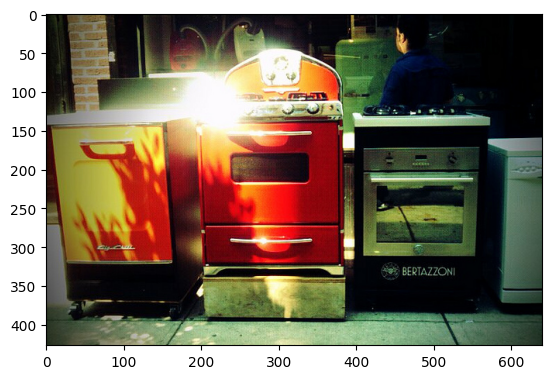

In [ ]:
question, answer, img_path, img_filename = dataset[14]
print(question)
print(answer)
print(img_path)
print(img_filename)
image = plt.imread(img_path)
plt.imshow(image)

In [ ]:
def normalize_answer(ans: str) -> str:
    prefixes = ["a ", "A ", "The ", "the ", "An ", "an "]
    for prefix in prefixes:
        if ans and ans.startswith(prefix):
            ans = ans[len(prefix):]
            break
    if ans and ans[0].isupper():
        ans = ans[0].lower() + ans[1:]
    if ans and ans[-1] in [".", '!']:
        ans = ans[:-1]
    return(ans)

def compare_answers(model_ans: str, gt_ans: List[str]) -> bool:
    for gt in gt_ans:
        if normalize_answer(model_ans) == normalize_answer(gt):
            return True
    return False


def test_functions():
    q1 = "what is the object the girl holding used to"
    print(normalize_answer("xdxdxd"))
    print(normalize_answer("a xdxdxd"))
    print(normalize_answer("A the xdxdxd"))

    print(compare_answers("ziemniak", ["jajko", "kubuś"]))
    print(compare_answers("a ziemniak", ["a jajko", "A kubuś"]))
    print(compare_answers("a ziemniak", ["ziemniak", "A ziemniak"]))
    print(compare_answers("a ziemniak!", ["ziemniak", "A ziemniak"]))


test_functions()

100%|██████████| 8352/8352 [00:00<00:00, 91662.22it/s]


number of questions starting with a lowercase:  0
number of questions without a question mark:  0
number of questions with multiple answers: 7
lengths of answers: {1: 7371, 3: 131, 2: 779, 4: 41, 6: 10, 5: 17, 10: 1, 18: 1, 8: 1}
number of answers with prefixes: 347
number of person:  182
number of people:  88
{<class 'list'>: 8352}


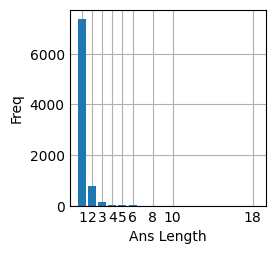

In [ ]:
# statistics of the dataset
def plot_a_histogram(my_dict):
    lengths = list(my_dict.keys())
    counts = list(my_dict.values())
    plt.style.use('_mpl-gallery')
    plt.bar(lengths, counts, width=0.8)
    plt.xlabel('Ans Length')
    plt.ylabel('Freq')
    plt.xticks(lengths)
    plt.show()

def examine_dataset(dataset):
    count_lowercase_question = 0
    questions_without_a_qm = 0
    multiple_answers = 0
    answer_length_count = {}
    answer_types = {}
    how_many_answers_with_prefixes = 0
    count_people = 0
    count_person = 0


    prefixes = ["A ", "a ", "The ", "the ", "An ", "an "]

    for q, a, f, i in tqdm(dataset):
        if q and q[0].islower():
                count_lowercase_question += 1
        if q and q[-1] != "?":
                questions_without_a_qm += 1
        if len(a) > 1:
            multiple_answers += 1

        if normalize_answer(a[0]) == "person":
            count_person += 1

        if normalize_answer(a[0]) == "people":
            count_people += 1

        ans_length = len(a[0].split())
        if ans_length in answer_length_count:
            answer_length_count[ans_length] += 1
        else:
            answer_length_count[ans_length] = 1

        for prefix in prefixes:
            if a[0].startswith(prefix):
                how_many_answers_with_prefixes += 1
                break
        if type(a) in answer_types:
            answer_types[type(a)] += 1
        else:
            answer_types[type(a)] = 1

    print("number of questions starting with a lowercase: ", count_lowercase_question)
    print("number of questions without a question mark: ", questions_without_a_qm)
    print("number of questions with multiple answers:", multiple_answers)
    print("lengths of answers:", answer_length_count)
    print("number of answers with prefixes:", how_many_answers_with_prefixes)
    print("number of person: ", count_person)
    print("number of people: ", count_people)
    print(answer_types)

    plot_a_histogram(answer_length_count)

examine_dataset(dataset)

In [ ]:
kb_path = '/kaggle/input/fvqa-base/new_dataset_release/all_fact_triples_release.json'
with open(kb_path, 'r') as file:
    kb = json.load(file)

def describe_knowledge_base(kb):
    relations = dict()
    relations_r = set()
    contexts = set()
    for e in kb.values():
        if e['r'][:2] == '/r':
            relations_r.add(e['r'])
        else:
            relations[e['r']] = e['surface']
        contexts.add(e.get('context', None))

    print('number of entries in knowledge base:', len(kb))
    print('number of types of relations in knowledge base:', len(relations) + len(relations_r))
    print('example of specific relation:\n', next(iter(relations.items())))
    print('list of common relations')
    print(relations_r)
    print('list of contexts')
    print(contexts)

describe_knowledge_base(kb)

number of entries in knowledge base: 225434
number of types of relations in knowledge base: 2339
example of specific relation:
 ('long#f', '[[leon truck]] are much longer than [[car]]')
list of common relations
{'/r/NotMadeOf', '/r/IsA', '/r/SymbolOf', '/r/dbpedia/genre', '/r/dbpedia/influenced', '/r/DesireOf', '/r/dbpedia/field', '/r/HasProperty', '/r/dbpedia/mainInterest', '/r/PartOf', '/r/NotCapableOf', '/r/NotHasA', '/r/SimilarSize', '/r/RelatedTo', '/r/NotHasProperty', '/r/InstanceOf', '/r/MadeOf', '/r/NotIsA', '/r/EtymologicallyDerivedFrom', '/r/CapableOf', '/r/LocationOfAction', '/r/HasPrerequisite', '/r/AtLocation', '/r/ReceivesAction', '/r/CreatedBy', '/r/DefinedAs', '/r/HasFirstSubevent', '/r/dbpedia/notableIdea', '/r/MotivatedByGoal', '/r/LocatedNear', '/r/HasLastSubevent', '/r/dbpedia/knownFor', '/r/Causes', '/r/NotDesires', '/r/Antonym', '/r/Synonym', '/r/UsedFor', '/r/DerivedFrom', '/r/CausesDesire', '/r/dbpedia/influencedBy', '/r/Desires', '/r/HasSubevent', '/r/HasA'}
li

In [ ]:
import transformers
import torch
from transformers import AutoTokenizer


model = model_paths[MODEL_NAME]
tokenizer = AutoTokenizer.from_pretrained(model)
pipeline = transformers.pipeline(
    "text-generation",
    model=model,
    torch_dtype=torch.float16,
    device_map="auto",
)


def query_model(
        system_message,
        user_message,
        temperature=0.7,
        max_length=1024
        ):
    messages = [
        {"role": "system", "content": system_message},
        {"role": "user", "content": user_message},
        ]
    prompt = pipeline.tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
        )
    terminators = [
        pipeline.tokenizer.eos_token_id,
        pipeline.tokenizer.convert_tokens_to_ids("<|eot_id|>")
    ]
    sequences = pipeline(
        prompt,
        do_sample=True,
        top_p=0.9,
        temperature=temperature,
        num_return_sequences=1,
        eos_token_id=terminators,
        max_new_tokens=max_length,
        return_full_text=False,
        pad_token_id=pipeline.model.config.eos_token_id
    )
    answer = sequences[0]['generated_text']

    return answer


Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.
2024-07-01 18:59:32.443728: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-07-01 18:59:32.443795: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-07-01 18:59:32.445272: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.


In [ ]:
system_message = """
You are an AI assistant designed to answer simple questions based on the image caption context.
Your answers should be as short as possible, usually a few words but sometimes maybe longer.
"""

response = query_model(
    system_message,
    user_message='Context: A forest. Question: What object has leaves and is about 20m tall? Answer:',
    temperature=1,
    max_length=256)

print(response)

A tree.


In [ ]:
from transformers import Blip2Processor, Blip2ForConditionalGeneration
import torch
from torch import cuda
from PIL import Image
import requests

class BLIP():
    def __init__(self):
        self.processor = Blip2Processor.from_pretrained("Salesforce/blip2-opt-2.7b")
        self.model = Blip2ForConditionalGeneration.from_pretrained(
            "Salesforce/blip2-opt-2.7b",
            torch_dtype=torch.float16,
            device_map='auto'
        )
        self.model.hf_device_map = 'language_model'
        self.device = "cuda" if torch.cuda.is_available() else "cpu"

    def img_to_caption(self, img, printing=False):
        inputs = self.processor(images=img, return_tensors="pt").to(self.device, torch.float16)

        generated_ids = self.model.generate(**inputs)
        generated_text = self.processor.batch_decode(generated_ids, skip_special_tokens=True)[0].strip()

        if printing:
            print("caption: ", generated_text)
            plt.imshow(img)

        return generated_text

    def question_to_answer(self, img, question, printing=False, answer=None):
        prompt = "Question: " + question + "? Answer:"
        inputs = self.processor(images=img, text=prompt, return_tensors="pt").to(self.device, torch.float16)

        generated_ids = self.model.generate(**inputs, max_length=51)
        generated_text = self.processor.batch_decode(generated_ids, skip_special_tokens=True)[0].strip()

        if printing:
            print(question, "\n", generated_text)
            plt.imshow(img)
            if answer is not None:
                print("correct answer: ", answer, "\n")
                print("we count is as: ", compare_answers(generated_text, answer))

        return generated_text


blip = BLIP()


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

caption:  a polar bear is sitting on a rock
Which animal in this picture can be found at a zoo? 
 polar bear
correct answer:  ['polar bear'] 

we count is as:  True


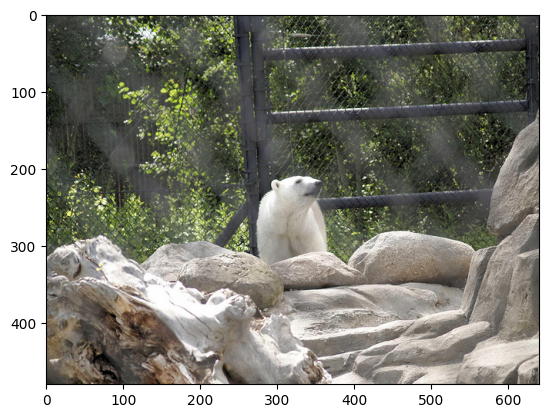

caption:  a bedroom with a bed, a dresser, a bookcase and a window
What is this place used as? 
 A bedroom
correct answer:  ['Bedroom.'] 

we count is as:  True


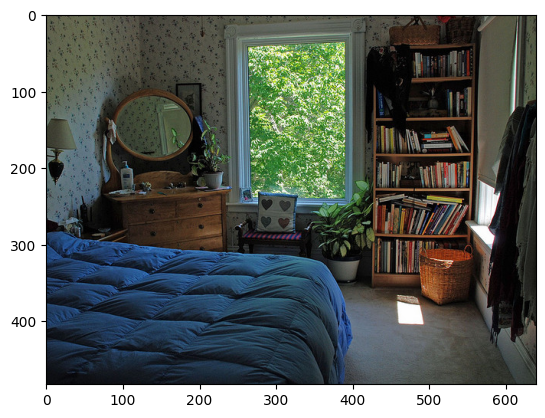

caption:  a bunch of bananas
Which object in this image is yellow? 
 Bananas
correct answer:  ['Banana'] 

we count is as:  False


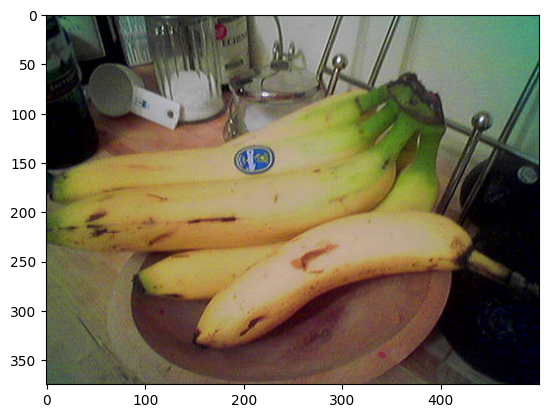

caption:  a man holding a tennis racket and a ball on a tennis court
Which object in this image desires haircut? 
 A tennis racket
correct answer:  ['a person'] 

we count is as:  False


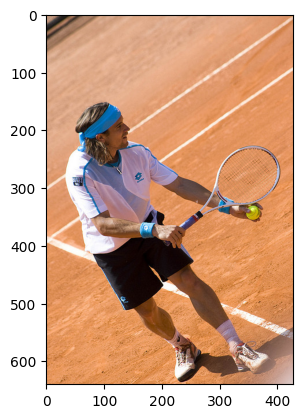

caption:  a man holding a tennis racket and a ball on a tennis court
What can you see in this image is related to strike? 
 The man is playing tennis
correct answer:  ['tennis racket'] 

we count is as:  False


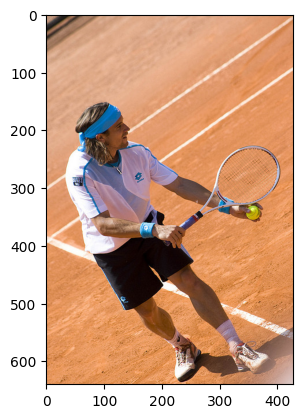

In [ ]:
def test_blip(blip):
    for i, (question, answer, img_path, img_filename) in enumerate(train_dataset):
        if i >= 5:
            break
        img = plt.imread(img_path)
        blip.img_to_caption(img, printing=True)
        blip.question_to_answer(img, question, printing=True, answer=answer)
        plt.show()
test_blip(blip)

In [ ]:
!pip install -Uq langchain chromadb langchain-community langchain-core sentence-transformers

/opt/conda/lib/python3.10/pty.py:89: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


In [ ]:
from torch import cuda, float16
import transformers
from langchain.embeddings import HuggingFaceEmbeddings
from langchain.vectorstores import Chroma

persist_directory = '/kaggle/working/vectorstore_kb'
collection_name = 'vectorstore_kb'
embedding_model_name = "sentence-transformers/all-mpnet-base-v2"
model_kwargs = {"device": "cuda:0"}
embedding_model = HuggingFaceEmbeddings(model_name=embedding_model_name, model_kwargs=model_kwargs)

if not os.path.exists(persist_directory):
    def extract_surface(element):
        return element['surface'].replace('[', '').replace(']', '')

    kb_surface = list(map(extract_surface, kb.values()))
    ids=[str(i) for i in range(len(kb_surface))]
    metadatas=list(kb.values())
    chunk_size = 10000

    for i in tqdm(range(0, len(kb_surface), chunk_size)):
        vectorstore_kb = Chroma.from_texts(
            kb_surface[i:i + chunk_size],
            embedding_model,
            ids=ids[i:i + chunk_size],
            metadatas=metadatas[i:i + chunk_size],
            collection_name=collection_name,
            persist_directory=persist_directory
        )

vectorstore_kb = Chroma(persist_directory=persist_directory, embedding_function=embedding_model, collection_name=collection_name)

def test_vectorstore_kb(vectorstore_kb):
    matches = vectorstore_kb.similarity_search('What is a toilet usually used for?', 10)
    for i in matches:
        print(i.page_content)
test_vectorstore_kb(vectorstore_kb)

/opt/conda/lib/python3.10/site-packages/langchain_core/_api/deprecation.py:139: LangChainDeprecationWarning: The class `HuggingFaceEmbeddings` was deprecated in LangChain 0.2.2 and will be removed in 0.3.0. An updated version of the class exists in the langchain-huggingface package and should be used instead. To use it run `pip install -U langchain-huggingface` and import as `from langchain_huggingface import HuggingFaceEmbeddings`.
  warn_deprecated(
/opt/conda/lib/python3.10/site-packages/huggingface_hub/file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


a toilet is for peeing
a toilet is for cleaning
a toilet is for pooping
toilet is related to for pooping
a toilet is a kind of commode.
toilet is for shitting
a toilet can be used for defecating
toilets can be used for excretion.
toilet is related to in bathroom
A toilet is where one urinates and defecates


In [ ]:
State: TypeAlias = dict[str, object]

def agent(model_type: str | None=None) -> callable:
    def _agent(func: callable):
        class __agent():
            def __init__(self,
                        func: callable,
                        model_type: str | None):
                self.func: callable = func
                self.model_type: str | None = model_type
                self.model = None

            def __call__(self, state: State, *args, **kwargs):
                return self.func(state, self.model, *args, **kwargs)

        return __agent(func, model_type)
    return _agent

# Usage example

def largelasagniamaker(state: State) -> None:
    state["Kanapka"] += " przełożone lasagnią"

llm = largelasagniamaker

@agent('robot kuchenny')
def kreator_kanapek(state: State, model) -> State:
    model(state)
    return state

print(kreator_kanapek.model_type)
kreator_kanapek.model = llm
example_state: State = {"Kanapka" : "Dwie kromki"}
print(kreator_kanapek(example_state))

robot kuchenny
{'Kanapka': 'Dwie kromki przełożone lasagnią'}


In [ ]:
@agent('vlm')
def vlm_caption_agent(state: State, model) -> State:
    """Process 'input_img' to produce 'vlm_caption'."""
    if 'input_img' in state:
        input_img = state['input_img']
    else:
        input_img = plt.imread(state['input_img_path'])
    caption = model.img_to_caption(input_img)
    state['vlm_caption'] = f'The image shows {caption}.'
    return state

@agent('vlm')
def vlm_question_agent(state: State, model) -> State:
    """Process 'input_img' and 'vlm_question' to produce 'vlm_answer'."""
    if 'input_img' in state:
        input_img = state['input_img']
    else:
        input_img = plt.imread(state['input_img_path'])
    if state['vlm_question'].count(' ') > 25:
        print(state['vlm_question'])
        state['vlm_question'] = 'What is in the background?'
    input_text = state['vlm_question']
    answer = model.question_to_answer(input_img, input_text)
    state['vlm_answer'] = answer
    return state

@agent('llm')
def llm_agent(state: State, model) -> State:
    """Process 'llm_prompt' to produce 'llm_response'. Format prompt using state dict entries."""
    response = query_model(
        system_message=state['llm_role'],
        user_message=state['llm_prompt'],
        temperature=0.3,
        max_length=256)

    state['llm_response'] = response
    return state

@agent('rag')
def rag_hint_agent(state: State, model) -> dict:
    """Process 'rag_prompt' to produce 'rag_retrievals' - concatenated hints."""

    matches = model.similarity_search(state['rag_prompt'], 5)
    texts = [m.page_content for m in matches]
    state['rag_retrievals'] = '. '.join(texts)
    return state

def remap_state(mapping: dict[str, str | list[str]]) -> callable:
    """Remap state dictionary entries according to dict 'mapping'."""
    @agent()
    def _remap(state: State, none: None=None) -> State:
        for from_key, to_keys in mapping.items():
            value = state[from_key]
            if isinstance(to_keys, str):
                state[to_keys] = value
            else:
                for to_key in to_keys:
                    state[to_key] = value
        return state
    return _remap

def prompt_maker(
    llm_prompt_template: str | None = None,
    llm_role: str | None = None,
    rag_prompt_template: str | None = None
) -> callable:
    @agent()
    def _prompt_maker(state: State, none: None=None) -> State:
        if llm_prompt_template:
            state['llm_prompt'] = llm_prompt_template.format(**state)
        if llm_role:
            state['llm_role'] = llm_role.format(**state)
        if rag_prompt_template:
            state['rag_prompt'] = rag_prompt_template.format(**state)
        return state
    return _prompt_maker


Agent: TypeAlias = type(vlm_caption_agent)

def do_while_agent(max_iters: int, *agents: Agent) -> callable:
    @agent('all')
    def _do_while_agent(state: State, model) -> State:
        state['iter'] = 0
        while(state['iter'] < max_iters):
            for agent in agents:
                agent.model = model[agent.model_type]
                state = agent(state)
            state['iter'] = state['iter'] + 1
        return state

    _do_while_agent
    return _do_while_agent

def add_to_context(*fields: str) -> callable:
    @agent()
    def _add_to_context(state: State, none: None=None) -> State:
        for field in fields:
            state['context'] = state.get('context', '') + f'{field}: {state[field]}\n'
        return state
    return _add_to_context


class MultiAgentSystem():
    '''
    Class implementing a multiagent system. To run agents
    use self.run(<dict with new input values | None>)
    values not included in the dict are reseted to their default
    values

    self.state  - current state of multi agent system (all current outputs and inputs)
    self.agents - a list of objects created by an "agent" decorator
    self.model  - a dict translating model type to some specific model
    '''

    def __init__(self, agents: list[Agent],
                       models: dict[str, object]) -> None:
        self.agents: list[Agent] = agents
        self.models: dict[str, object] = models
        self.models[None] = None
        self.models['all'] = self.models
        self._init_agents()

    def _init_agents(self) -> None:
        for agent in self.agents:
            agent.model = self.models[agent.model_type]

    def _reset_state(self, input: State) -> None:
        self.state = input.copy()

    def run_agents(self, input: State) -> list[State]:
        """Run specified agents sequentially and return list of intermediate states."""
        self._reset_state(input)
        intermediate_states: list[State] = []
        for agent in self.agents:
            self.state = agent(self.state)
            intermediate_states.append(self.state.copy())
        return intermediate_states


In [ ]:
llm_image_question_role = """
    You are an AI assistant designed to ask a new question about an image.
    You are given an original question refers to the image and you are provided with the image caption.
    Your answer should contain exactly one follow-up question about the image.
    Don't answer the main question. Don't write anything else apart from the follow-up question.
    """

llm_reasoner_role = """
    You are an AI assistant, a part of multi agent system, designed to make one step of reasoning to answer a question.
    The question refers to the image and you are provided with the image caption.
    Also you will receive a hint from knowledge base.
    Your answer should contain exactly one follow-up question delegated to knowledge base.
    Knowledge base doesn't see the image, so don't refer to the image in the follow-up question.
    """
llm_reasoner_prompt_template = 'Context: {context} Question: {orig_question} Follow-up question:'

rag_prompt_template = '{context} {rag_question}'

llm_integrator_role = """
    You are an AI assistant designed to answer simple questions based on the image caption.
    Your answers should be as short as possible, referring to a single thing.
    """
llm_integrator_prompt_template = 'Context: {context} Question: {orig_question} Answer:'

feedback_loop_multiagent = MultiAgentSystem(
        agents = [
            vlm_caption_agent,
            add_to_context('vlm_caption'),

            remap_state({'orig_question': 'rag_question'}),
            prompt_maker(rag_prompt_template=rag_prompt_template),
            rag_hint_agent,
            add_to_context('rag_retrievals'),

            do_while_agent(1,
                prompt_maker(llm_role=llm_image_question_role, llm_prompt_template=llm_reasoner_prompt_template),
                llm_agent,
                remap_state({'llm_response': 'vlm_question'}),
                vlm_question_agent,
                add_to_context('vlm_question', 'vlm_answer'),
            ),

            prompt_maker(llm_prompt_template=llm_integrator_prompt_template, llm_role=llm_integrator_role),
            llm_agent,
        ],
        models = {
            "vlm": blip,
            "llm": pipeline,
            "rag": vectorstore_kb
        }
)

feedback_loop_results = []
good_direct, good_llm, total = 0, 0, 0
for i, (question, answer, img_path, img_filename) in (pbar := tqdm(enumerate(test_dataset))):
    if len(plt.imread(img_path).shape) not in [3, 4]:
        print(i, img_path)
        continue
    task = {
        'orig_question': question,
        'question': question,
        'input_img_path': img_path,
    }
    states = feedback_loop_multiagent.run_agents(task)
    correct_answer = compare_answers(states[-1]['llm_response'], answer)
    final_state = states[-1]
    final_state['correct_answer_direct'] = correct_answer
    final_state['answer'] = '|'.join(answer)
    if correct_answer:
        good_direct += 1
    total += 1
    feedback_loop_results.append(final_state)
    pbar.set_postfix(accuracy=good_direct / total, good_predictions=good_direct)

91it [00:21,  4.26it/s, accuracy=0.374, good_predictions=34]
